In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv("powerplant_data.csv")

In [4]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
X=df.drop("PE",axis=1)
y=df["PE"]

In [7]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [8]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [9]:
X_test

,AT,V,AP,RH
2513,29.70,57.35,1005.63,57.35
9411,25.71,71.64,1008.85,77.31
8745,17.83,44.92,1025.04,70.58
9085,9.46,41.40,1026.78,87.58
4950,29.90,64.79,1016.90,48.24
...,...,...,...,...
7204,20.46,51.43,1010.06,83.79
1599,29.70,67.17,1007.31,66.56
5697,14.64,39.58,1011.46,71.90
350,29.47,71.32,1008.07,67.00


In [10]:
df.shape

(9568, 5)

In [11]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [12]:
X_train_scaled

array([[ 0.74805289,  0.72006931, -0.32660017, -0.49711722],
       [ 0.86181948,  1.26515721, -0.98521113,  0.8181501 ],
       [ 0.93409473,  1.52314975,  0.32523844,  0.80167494],
       ...,
       [-0.22097078, -0.834965  ,  0.36756563, -0.83554456],
       [ 0.94747903,  1.14245344, -0.41971997, -0.45455637],
       [-1.77355014, -1.19049131,  1.92520594,  0.91837402]],
      shape=(7654, 4))

In [13]:
X_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]],
      shape=(1914, 4))

In [14]:
import torch
import torch.nn as nn

In [15]:
X_train_tensor=torch.tensor(X_train_scaled,dtype=torch.float32)
X_test_tensor=torch.tensor(X_test_scaled,dtype=torch.float32)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)

In [16]:
X_train_tensor

tensor([[ 0.7481,  0.7201, -0.3266, -0.4971],
        [ 0.8618,  1.2652, -0.9852,  0.8182],
        [ 0.9341,  1.5231,  0.3252,  0.8017],
        ...,
        [-0.2210, -0.8350,  0.3676, -0.8355],
        [ 0.9475,  1.1425, -0.4197, -0.4546],
        [-1.7736, -1.1905,  1.9252,  0.9184]])

In [17]:
y_train_tensor

tensor([[442.7500],
        [432.5200],
        [428.8000],
        ...,
        [464.2600],
        [440.4500],
        [484.4400]])

In [18]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset=TensorDataset(X_train_tensor,y_train_tensor)
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

In [19]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32,shuffle=True)

In [26]:
# Deep learning
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()
        self.model=nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),
            # 2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU() ,
    
            # output layer
            nn.Linear(6,1),
        )

    def forward(self,x):
        return self.model(x)
        

In [30]:
import torch.optim as optim
model=ANN()

# Loss, Optimiser

crietrion=nn.MSELoss()
optimizer=optim.Adam(model.parameters())


In [33]:
# train ANN'
train_losses=[]
val_losses=[]
epochs=100
best_val_loss = float("inf")
for epoch in range(epochs):
    model.train()
    running_loss=0.0 
    for xb,yb in train_loader:
        # xb- fearures of 1 batch
        # yb- labels of 1 batch
        optimizer.zero_grad()
        outputs=model(xb)
        loss= crietrion(outputs, yb)

        loss.backward()

        optimizer.step()

        running_loss+=loss.item()
    epoch_train_loss=running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)

    
    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): # no gradients compute
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") #.pt or .pth

epoch 1/100 ==> train loss = 181288.597265625 & val loss = 164338.84375
epoch 2/100 ==> train loss = 141703.79977213542 & val loss = 117120.296875
epoch 3/100 ==> train loss = 92489.13149414063 & val loss = 69423.1640625
epoch 4/100 ==> train loss = 52043.337556966144 & val loss = 38196.3203125
epoch 5/100 ==> train loss = 30389.512060546876 & val loss = 24881.224609375
epoch 6/100 ==> train loss = 22013.229447428384 & val loss = 19826.75390625
epoch 7/100 ==> train loss = 18350.70604248047 & val loss = 16830.794921875
epoch 8/100 ==> train loss = 15561.064971923828 & val loss = 14139.7353515625
epoch 9/100 ==> train loss = 12952.401672363281 & val loss = 11576.271484375
epoch 10/100 ==> train loss = 10430.158666992187 & val loss = 9114.6943359375
epoch 11/100 ==> train loss = 8078.058427937825 & val loss = 6865.1142578125
epoch 12/100 ==> train loss = 5952.251635742187 & val loss = 4888.64990234375
epoch 13/100 ==> train loss = 4129.158422342936 & val loss = 3276.959716796875
epoch 14

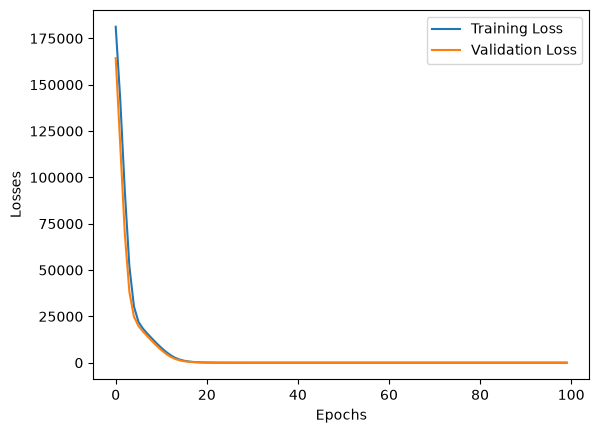

In [34]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [35]:
# Loading the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [36]:
# Evaluation

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 20.489057540893555
Testing MSE: 18.776702880859375


In [37]:
from sklearn.metrics import r2_score

print("r^2 score =", r2_score(y_test, test_preds))

r^2 score = 0.9343802670700766


In [38]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,434.991913,433.27
1,436.781342,438.16
2,461.454102,458.42
3,476.488190,480.82
4,435.260010,441.41
...,...,...
1909,451.233063,456.70
1910,431.428528,438.04
1911,467.441864,467.80
1912,430.880188,437.14
